# M7.4 · 配对 / 统计套利

> 配对交易找两个长期协整的资产，价差偏离时做多弱者、做空强者，
> 赌价差均值回归，整体保持市场中性。

## 一、机制

1. **协整（Engle-Granger）**：OLS 求对冲比，对价差做 ADF 检验；
2. **价差 z-score**：标准化后超 ±2 开仓、回归 0 平仓；
3. **半衰期**：衡量均值回归速度，决定持仓周期。

## 二、协整与信号

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np
from deriv_lab import pairs
rng = np.random.default_rng(3)
x = np.cumsum(rng.normal(0, 1, 300)) + 50
y = 2*x + rng.normal(0, 0.5, 300)
beta = pairs.hedge_ratio(y, x); sp = pairs.spread(y, x, beta)
z = pairs.zscore(sp); stat, pv = pairs.coint_adf(sp)
sig = pairs.pairs_signal(z)
print('对冲比=%.3f 协整ADF p=%.4f 信号非零占比=%.2f 半衰期=%.2f'
      % (beta, pv, (sig != 0).mean(), pairs.half_life(sp)))

对冲比=2.003 协整ADF p=0.0000 信号非零占比=0.12 半衰期=0.72


## 三、可视化：价差与信号

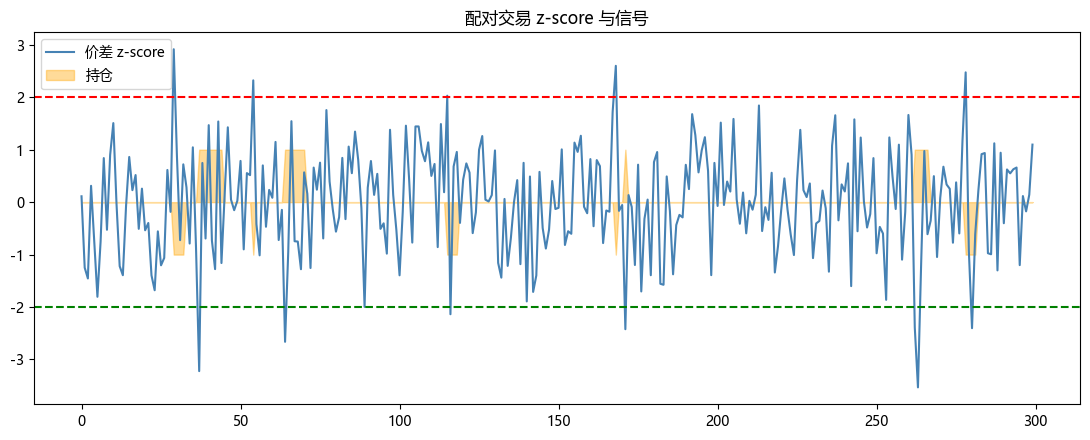

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(z, color='steelblue', label='价差 z-score')
ax.axhline(2, color='red', ls='--'); ax.axhline(-2, color='green', ls='--')
ax.fill_between(range(300), sig, 0, color='orange', alpha=0.4, label='持仓')
ax.set_title('配对交易 z-score 与信号'); ax.legend()
plt.tight_layout(); plt.show()

## 四、面试要点

- **协整与相关的区别？** 相关衡量共同变动，协整要求两者线性组合平稳、价差可均值回归。
- **ADF 检验的原假设？** 存在单位根（不平稳），p 小则拒绝、支持协整。
- **为什么用 z-score 而非绝对价差？** 标准化后阈值有统一口径，便于跨品种比较。
- **配对交易的风险？** 协整关系破裂（结构性变化）、价差继续发散、成本与融券限制。

## 五、练习

1. 用滚动窗口估计动态对冲比。
2. 实现 Johansen 多资产协整。
3. 加入交易成本评估配对收益。
4. 在真实 ETF/股票对上验证。